# Sesi 1 — Eksplorasi Data (EDA) NSL-KDD

**Workshop Deep Learning untuk Mahasiswa Teknik Telekomunikasi — ITERA**

Sebelum melatih ANN, kita perlu **mengenal datanya dulu**. *Exploratory Data Analysis* (EDA) menjawab pertanyaan seperti: fitur apa saja yang ada? Apakah datanya bersih? Seimbangkah jumlah koneksi normal dan serangan? Fitur mana yang membedakan keduanya? Jawaban-jawaban ini menentukan langkah *preprocessing* di `train.py`.

| Bagian | Isi |
|---|---|
| 1 | Memuat data KDDTrain+ dan KDDTest+ |
| 2 | Struktur data & kelompok fitur |
| 3 | Kualitas data: *missing value*, duplikat, fitur konstan |
| 4 | Label: jenis serangan, kategori, ketidakseimbangan kelas |
| 5 | Fitur kategorikal: `protocol_type`, `service`, `flag` |
| 6 | Fitur numerik: skala, sebaran, normal vs serangan |
| 7 | Korelasi antar fitur dan dengan label |
| 8 | Perbedaan data latih vs data uji |
| 9 | Ringkasan temuan → keputusan *preprocessing* |

**Cara menjalankan:** `uv sync` lalu `uv run jupyter lab`, buka notebook ini (`sesi-1-ann/eda_nslkdd.ipynb`), dan jalankan sel dari atas ke bawah (`Shift + Enter`). Dataset diunduh otomatis ke `sesi-1-ann/data/` jika belum ada.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import config                  # daftar kolom & lokasi file (dipakai juga oleh train.py)
from data import load_nslkdd   # fungsi unduh + baca NSL-KDD

# Palet warna ITERA (sama dengan slide)
NAVY, NAVY2, GOLD, RED, TEAL, PURPLE, GRAY = "#0B1F3A", "#1B3A5C", "#D4A017", "#C8102E", "#1E8C8C", "#8E5BA8", "#5A5A5A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
print("pandas", pd.__version__)

pandas 3.0.6


---
## 1. Memuat Data

NSL-KDD (Tavallaee dkk., 2009) adalah versi perbaikan dataset KDD Cup 99. Setiap **baris = satu koneksi jaringan** yang dirangkum menjadi 41 fitur, ditambah dua kolom tambahan:

- `label` — nama serangan (`neptune`, `smurf`, ...) atau `normal`
- `difficulty` — tingkat kesulitan record (dibahas di Bagian 8)

Kita pakai fungsi `load_nslkdd()` yang sama dengan `train.py`, sehingga data yang dieksplorasi **persis** data yang nanti dilatih.

In [2]:
train_df, test_df = load_nslkdd()
train_df.head()

KDDTrain+: 125,973 koneksi | KDDTest+: 22,544 koneksi


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
print("Ukuran KDDTrain+ (baris, kolom):", train_df.shape)
print("Ukuran KDDTest+  (baris, kolom):", test_df.shape)
print(f"Perbandingan latih : uji = {len(train_df) / len(test_df):.1f} : 1")

Ukuran KDDTrain+ (baris, kolom): (125973, 43)
Ukuran KDDTest+  (baris, kolom): (22544, 43)
Perbandingan latih : uji = 5.6 : 1


---
## 2. Struktur Data & Kelompok Fitur

41 fitur NSL-KDD terbagi menjadi empat kelompok berdasarkan cara fitur itu diekstrak dari trafik:

| Kelompok | Kolom | Makna |
|---|---|---|
| **Dasar** | 1–9 | Informasi header koneksi TCP/IP: durasi, protokol, layanan, jumlah *byte* |
| **Konten** | 10–22 | Isi *payload*: gagal *login*, akses *root*, pembuatan file |
| **Trafik (2 detik)** | 23–31 | Statistik koneksi ke host/layanan yang sama dalam 2 detik terakhir |
| **Trafik (host tujuan)** | 32–41 | Statistik 100 koneksi terakhir ke host tujuan yang sama |

In [4]:
FEATURES = config.COLUMNS[:41]          # 41 fitur (tanpa label & difficulty)
GROUPS = {
    "Dasar": FEATURES[:9],
    "Konten": FEATURES[9:22],
    "Trafik (2 detik)": FEATURES[22:31],
    "Trafik (host tujuan)": FEATURES[31:41],
}
for name, cols in GROUPS.items():
    print(f"{name:21s} {len(cols):2d} fitur: {', '.join(cols[:4])}, ...")

Dasar                  9 fitur: duration, protocol_type, service, flag, ...
Konten                13 fitur: hot, num_failed_logins, logged_in, num_compromised, ...
Trafik (2 detik)       9 fitur: count, srv_count, serror_rate, srv_serror_rate, ...
Trafik (host tujuan)  10 fitur: dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, ...


Berdasarkan **tipe datanya**, fitur dibagi menjadi *kategorikal* (teks) dan *numerik* (angka). Sebagian fitur numerik sebenarnya **biner** (hanya bernilai 0 atau 1), mis. `logged_in`.

In [5]:
categorical = config.CATEGORICAL                                   # fitur teks
numeric = [c for c in FEATURES if c not in categorical]            # fitur angka
binary = [c for c in numeric if train_df[c].nunique() == 2 and set(train_df[c].unique()) <= {0, 1}]

print(f"Kategorikal : {len(categorical)} -> {categorical}")
print(f"Numerik     : {len(numeric)} (termasuk {len(binary)} fitur biner)")
print(f"Fitur biner : {binary}")

Kategorikal : 3 -> ['protocol_type', 'service', 'flag']
Numerik     : 38 (termasuk 5 fitur biner)
Fitur biner : ['land', 'logged_in', 'root_shell', 'is_host_login', 'is_guest_login']


In [6]:
train_df.dtypes.value_counts()   # object = teks, int64/float64 = angka

int64      24
float64    15
str         4
Name: count, dtype: int64

---
## 3. Kualitas Data

Tiga pemeriksaan standar sebelum data dipakai:

1. ***Missing value*** — adakah sel kosong?
2. **Duplikat** — adakah baris yang persis sama? (masalah utama KDD Cup 99 yang diperbaiki di NSL-KDD)
3. **Fitur konstan** — kolom yang nilainya sama untuk semua baris tidak membawa informasi apa pun.

In [7]:
for name, df in [("KDDTrain+", train_df), ("KDDTest+", test_df)]:
    print(f"{name:10s} missing value: {df.isna().sum().sum():,} | baris duplikat: {df.duplicated().sum():,}")

KDDTrain+  missing value: 0 | baris duplikat: 0
KDDTest+   missing value: 0 | baris duplikat: 0


In [8]:
n_unique = train_df[FEATURES].nunique().sort_values()
print("Jumlah nilai unik paling sedikit:")
print(n_unique.head(8).to_string())

constant = n_unique[n_unique == 1].index.tolist()
print("\nFitur konstan:", constant)

Jumlah nilai unik paling sedikit:
num_outbound_cmds    1
is_host_login        2
is_guest_login       2
land                 2
logged_in            2
root_shell           2
protocol_type        3
wrong_fragment       3

Fitur konstan: ['num_outbound_cmds']


**Temuan:**
- Data **bersih** — tidak ada *missing value* maupun duplikat, jadi tidak perlu imputasi.
- `num_outbound_cmds` **selalu 0** → tidak berguna untuk model. Di *pipeline* kita kolom ini dibiarkan (setelah *standardization* nilainya tetap 0 sehingga tidak berpengaruh), tetapi boleh saja dibuang.
- `difficulty` **bukan fitur** koneksi, melainkan metadata dataset → dibuang sebelum training.

---
## 4. Label: Jenis & Kategori Serangan

### 4.1 Jenis serangan

Kolom `label` berisi nama serangan spesifik. Setiap jenis termasuk salah satu dari **empat kategori** (lihat slide *Kategori Serangan Jaringan*):

| Kategori | Arti | Contoh |
|---|---|---|
| **DoS** | *Denial of Service*: membanjiri layanan | `neptune` (SYN *flood*), `smurf` |
| **Probe** | Memindai jaringan mencari celah | `portsweep`, `ipsweep`, `nmap`, `satan` |
| **R2L** | *Remote to Local*: masuk dari luar tanpa akun sah | `guess_passwd`, `warezclient` |
| **U2R** | *User to Root*: menaikkan hak akses jadi *root* | `buffer_overflow`, `rootkit` |

In [9]:
ATTACK_CATEGORY = {
    # DoS
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS", "smurf": "DoS", "teardrop": "DoS",
    "apache2": "DoS", "mailbomb": "DoS", "processtable": "DoS", "udpstorm": "DoS",
    # Probe
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe", "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    # R2L
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    "warezclient": "R2L", "warezmaster": "R2L", "named": "R2L", "sendmail": "R2L", "snmpgetattack": "R2L",
    "snmpguess": "R2L", "worm": "R2L", "xlock": "R2L", "xsnoop": "R2L",
    # U2R
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R", "rootkit": "U2R",
    "httptunnel": "U2R", "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R",
}
CATEGORIES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
COLORS = {"Normal": TEAL, "DoS": RED, "Probe": GOLD, "R2L": NAVY2, "U2R": PURPLE}

for df in (train_df, test_df):
    df["category"] = df["label"].map(ATTACK_CATEGORY).fillna("Normal")   # "normal" tidak ada di kamus
    df["is_attack"] = (df["label"] != "normal").astype(int)              # label biner, sama dengan train.py

print("Jumlah jenis label di data latih:", train_df["label"].nunique(), "(termasuk normal)")

Jumlah jenis label di data latih: 23 (termasuk normal)


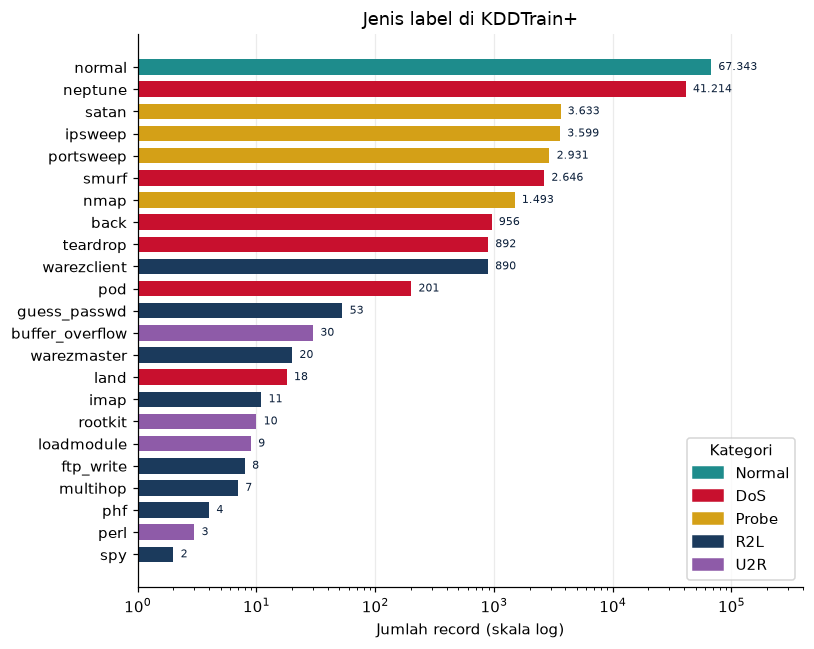

In [10]:
counts = train_df["label"].value_counts().sort_values()
colors = [COLORS[train_df.loc[train_df["label"] == lbl, "category"].iloc[0]] for lbl in counts.index]

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(counts.index, counts.values, color=colors, height=0.7)
for y, c in enumerate(counts.values):
    ax.text(c * 1.15, y, f"{c:,}".replace(",", "."), va="center", fontsize=7.5, color=NAVY)
ax.set_xscale("log")   # skala log: selisih jumlahnya ribuan kali lipat
ax.set_xlim(1, 4e5)
ax.set_xlabel("Jumlah record (skala log)")
ax.set_title("Jenis label di KDDTrain+")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=COLORS[k], label=k) for k in CATEGORIES], loc="lower right", title="Kategori")
plt.tight_layout()
plt.show()

Perhatikan **sumbu logaritmik**: `neptune` punya ~41 ribu record, sementara `spy` hanya 2. Tanpa skala log, batang kecil tidak akan terlihat sama sekali.

### 4.2 Ketidakseimbangan kelas (*class imbalance*)

In [11]:
summary = pd.DataFrame({
    "latih": train_df["category"].value_counts(),
    "uji": test_df["category"].value_counts(),
}).reindex(CATEGORIES)
summary["latih (%)"] = 100 * summary["latih"] / summary["latih"].sum()
summary["uji (%)"] = 100 * summary["uji"] / summary["uji"].sum()
summary.style.format({"latih": "{:,}", "uji": "{:,}", "latih (%)": "{:.2f}", "uji (%)": "{:.2f}"})

,latih,uji,latih (%),uji (%)
category,,,,
Normal,"67,343","9,711",53.46,43.08
DoS,"45,927","7,458",36.46,33.08
Probe,"11,656","2,421",9.25,10.74
R2L,995,"2,754",0.79,12.22
U2R,52,200,0.04,0.89


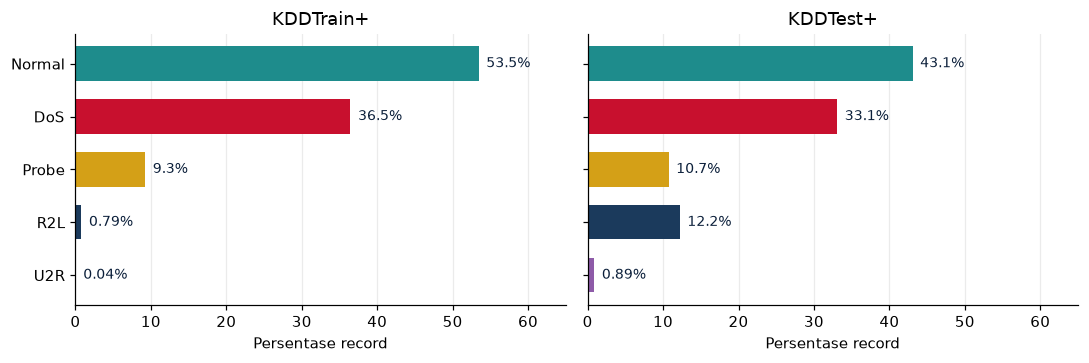

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, title in [(axes[0], "latih (%)", "KDDTrain+"), (axes[1], "uji (%)", "KDDTest+")]:
    values = summary[col][::-1]
    ax.barh(values.index, values.values, color=[COLORS[k] for k in values.index], height=0.65)
    for y, v in enumerate(values.values):
        ax.text(v + 1, y, f"{v:.2f}%" if v < 1 else f"{v:.1f}%", va="center", fontsize=9, color=NAVY)
    ax.set_xlim(0, 65)
    ax.set_xlabel("Persentase record")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Temuan:**
- Kelas **sangat tidak seimbang**: U2R hanya **0,04%** data latih (52 dari ~126 ribu record).
- Model yang "malas" dan selalu menebak *normal* sudah mendapat akurasi ~53% di data latih. Karena itu di evaluasi kita juga memakai ***precision*, *recall*, dan F1**, bukan akurasi saja.
- Proporsi kategori **berbeda** antara data latih dan uji: R2L naik dari 0,8% menjadi ~12%. Data uji sengaja dibuat lebih menantang.

### 4.3 Serangan yang hanya ada di data uji

In [13]:
new_attacks = sorted(set(test_df["label"]) - set(train_df["label"]))
is_new = test_df["label"].isin(new_attacks)

print(f"{len(new_attacks)} jenis serangan BARU (tidak pernah dilihat saat training):")
print(", ".join(new_attacks))
print(f"\nJumlah record: {is_new.sum():,} = {100 * is_new.mean():.1f}% dari data uji")
print("\nPer kategori:")
print(test_df.loc[is_new, "category"].value_counts().to_string())

17 jenis serangan BARU (tidak pernah dilihat saat training):
apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

Jumlah record: 3,750 = 16.6% dari data uji

Per kategori:
category
DoS      1717
Probe    1315
R2L       555
U2R       163


Hampir **1 dari 6** koneksi di data uji berasal dari serangan yang tidak ada di data latih. Ini meniru kondisi nyata: penyerang selalu membuat teknik baru. Model yang baik harus **menggeneralisasi** pola serangan, bukan menghafal nama serangannya.

### 4.4 Label biner untuk *hands-on*

Di `train.py` kita menyederhanakan masalah: **normal = 0**, **serangan apa pun = 1**.

In [14]:
binary_share = pd.DataFrame({
    "latih (%)": 100 * train_df["is_attack"].value_counts(normalize=True),
    "uji (%)": 100 * test_df["is_attack"].value_counts(normalize=True),
}).rename(index={0: "normal (0)", 1: "serangan (1)"})
binary_share.round(1)

,latih (%),uji (%)
is_attack,,
normal (0),53.5,43.1
serangan (1),46.5,56.9


Setelah digabung, kelas biner cukup **seimbang** (~53:47 di data latih). Meski begitu, `train.py` tetap memakai `stratify` saat memisahkan data validasi agar proporsi ini terjaga.

---
## 5. Fitur Kategorikal

Tiga fitur berupa teks: `protocol_type`, `service`, dan `flag`. Pertanyaannya: **apakah nilai fitur ini berhubungan dengan jenis serangan?**

In [15]:
for col in categorical:
    print(f"{col:14s}: {train_df[col].nunique():2d} nilai unik -> {train_df[col].value_counts().index[:6].tolist()} ...")

protocol_type :  3 nilai unik -> ['tcp', 'udp', 'icmp'] ...
service       : 70 nilai unik -> ['http', 'private', 'domain_u', 'smtp', 'ftp_data', 'eco_i'] ...
flag          : 11 nilai unik -> ['SF', 'S0', 'REJ', 'RSTR', 'RSTO', 'S1'] ...


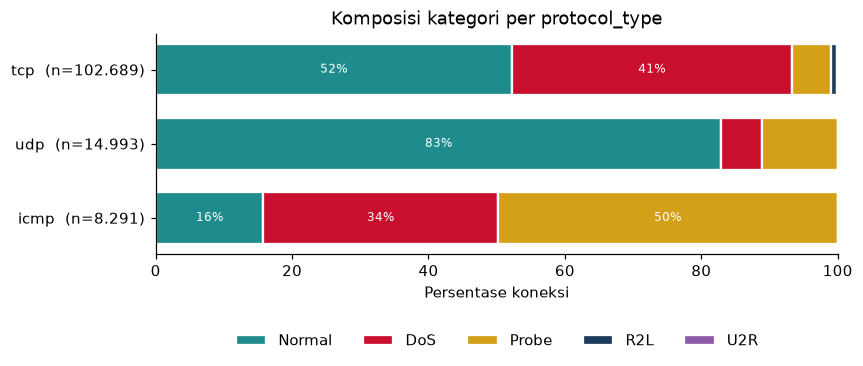

In [16]:
def stacked_share(ax, feature, order=None, title=None):
    # Batang 100%: komposisi kategori serangan untuk setiap nilai fitur
    table = pd.crosstab(train_df[feature], train_df["category"]).reindex(columns=CATEGORIES, fill_value=0)
    if order is not None:
        table = table.loc[order]
    share = 100 * table.div(table.sum(axis=1), axis=0)
    left = np.zeros(len(share))
    for cat in CATEGORIES:
        ax.barh(share.index, share[cat], left=left, color=COLORS[cat], label=cat,
                height=0.7, edgecolor="white", linewidth=1.5)
        for y, (l, v) in enumerate(zip(left, share[cat])):
            if v >= 12:   # label hanya di segmen yang cukup lebar
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
        left += share[cat].to_numpy()
    n = table.sum(axis=1)
    ax.set_yticks(range(len(share)), [f"{idx}  (n={c:,})".replace(",", ".") for idx, c in n.items()])
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase koneksi")
    ax.set_title(title or feature)
    ax.grid(False)
    ax.invert_yaxis()


fig, ax = plt.subplots(figsize=(8, 2.6))
stacked_share(ax, "protocol_type", order=["tcp", "udp", "icmp"], title="Komposisi kategori per protocol_type")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
plt.show()

- **TCP** mendominasi (~82%) dan berisi semua jenis serangan.
- **ICMP** didominasi serangan: `smurf` (DoS lewat *ping broadcast*) dan `ipsweep` (Probe dengan *ping*).
- **UDP** sebagian besar normal (mis. trafik DNS).

### 5.1 `service` — layanan tujuan (70 nilai)

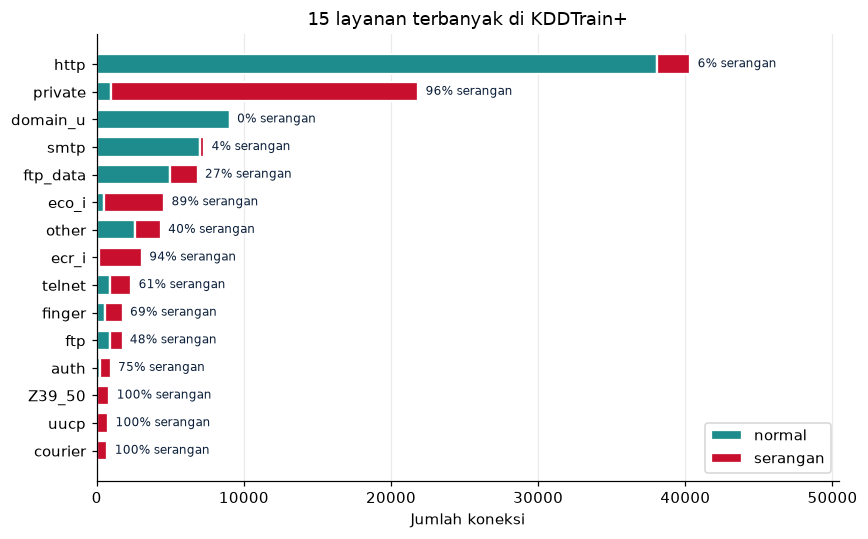

In [17]:
top_services = train_df["service"].value_counts().head(15).index
table = pd.crosstab(train_df["service"], train_df["is_attack"]).loc[top_services]
attack_rate = 100 * table[1] / table.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_services, table[0], color=TEAL, label="normal", height=0.7, edgecolor="white", linewidth=1.5)
ax.barh(top_services, table[1], left=table[0], color=RED, label="serangan", height=0.7, edgecolor="white", linewidth=1.5)
for y, (total, rate) in enumerate(zip(table.sum(axis=1), attack_rate)):
    ax.text(total + 500, y, f"{rate:.0f}% serangan", va="center", fontsize=8, color=NAVY)
ax.invert_yaxis()
ax.set_xlim(0, table.sum(axis=1).max() * 1.25)
ax.set_xlabel("Jumlah koneksi")
ax.set_title("15 layanan terbanyak di KDDTrain+")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

- `http` hampir seluruhnya **normal** (akses web biasa).
- `private` dan `ecr_i` didominasi **serangan**: `neptune` menyerang *port* acak (`private`), `smurf` memakai ICMP *echo request* (`ecr_i`).
- `eco_i` (ICMP *echo*) didominasi `ipsweep`: *ping* ke banyak alamat untuk mencari host yang hidup.
- Layanan jarang seperti `Z39_50`, `uucp`, dan `courier` **100% serangan**: koneksi ke sana hanya muncul saat penyerang memindai semua *port*.
- Banyak layanan lama (`telnet`, `uucp`, ...) muncul karena dataset ini direkam tahun 1998.

### 5.2 `flag` — status koneksi TCP

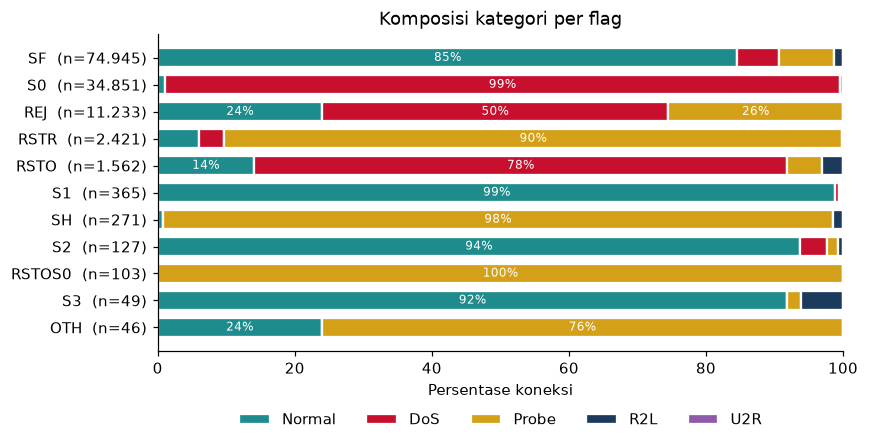

In [18]:
flag_order = train_df["flag"].value_counts().index
fig, ax = plt.subplots(figsize=(8, 4.2))
stacked_share(ax, "flag", order=flag_order, title="Komposisi kategori per flag")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()

Beberapa arti *flag* yang penting:

| *Flag* | Arti | Kaitan dengan serangan |
|---|---|---|
| `SF` | koneksi normal: dibuka & ditutup dengan benar | mayoritas normal |
| `S0` | paket SYN dikirim, **tidak ada balasan** | ciri khas **SYN *flood*** (`neptune`, DoS) |
| `REJ` | koneksi **ditolak** | `neptune` (DoS) & `satan` (Probe) |
| `RSTR` | koneksi diputus (RST) oleh penerima | `portsweep` (Probe) |
| `RSTO` | koneksi diputus (RST) oleh pengirim | `neptune` (DoS) |
| `SH` | SYN lalu langsung FIN, tanpa balasan | *stealth scan* `nmap` (Probe) |

Satu fitur sederhana seperti `flag = S0` saja sudah sangat kuat menandai serangan DoS.

### 5.3 Dampaknya: *one-hot encoding* → 122 fitur

Neuron hanya bisa menghitung angka, jadi setiap nilai teks diubah menjadi kolom 0/1 tersendiri:

In [19]:
n_onehot = {col: train_df[col].nunique() for col in categorical}
total = len(numeric) + sum(n_onehot.values())
print(f"{len(numeric)} numerik + " + " + ".join(f"{v} ({k})" for k, v in n_onehot.items()) + f" = {total} fitur")

missing_in_train = {col: set(test_df[col]) - set(train_df[col]) for col in categorical}
print("Nilai di data uji yang tidak ada di data latih:", missing_in_train)

38 numerik + 3 (protocol_type) + 70 (service) + 11 (flag) = 122 fitur
Nilai di data uji yang tidak ada di data latih: {'protocol_type': set(), 'service': set(), 'flag': set()}


Inilah asal angka **122** pada input MLP 122-64-32-1. Data uji hanya memakai 64 dari 70 layanan, sehingga `encode_features()` di `preprocessing.py` menyamakan kolomnya dengan data latih (`reindex`, kolom yang tidak ada diisi 0).

---
## 6. Fitur Numerik

### 6.1 Skala antar fitur sangat berbeda

In [20]:
stats = train_df[numeric].describe().T[["mean", "std", "min", "50%", "max"]]
stats.sort_values("max", ascending=False).head(10).style.format("{:,.2f}")

,mean,std,min,50%,max
src_bytes,"45,566.74","5,870,331.18",0.00,44.00,"1,379,963,888.00"
dst_bytes,"19,779.11","4,021,269.15",0.00,0.00,"1,309,937,401.00"
duration,287.14,"2,604.52",0.00,0.00,"42,908.00"
num_compromised,0.28,23.94,0.00,0.00,"7,479.00"
num_root,0.30,24.40,0.00,0.00,"7,468.00"
srv_count,27.74,72.64,0.00,8.00,511.00
count,84.11,114.51,0.00,14.00,511.00
dst_host_count,182.15,99.21,0.00,255.00,255.00
dst_host_srv_count,115.65,110.70,0.00,63.00,255.00
hot,0.20,2.15,0.00,0.00,77.00


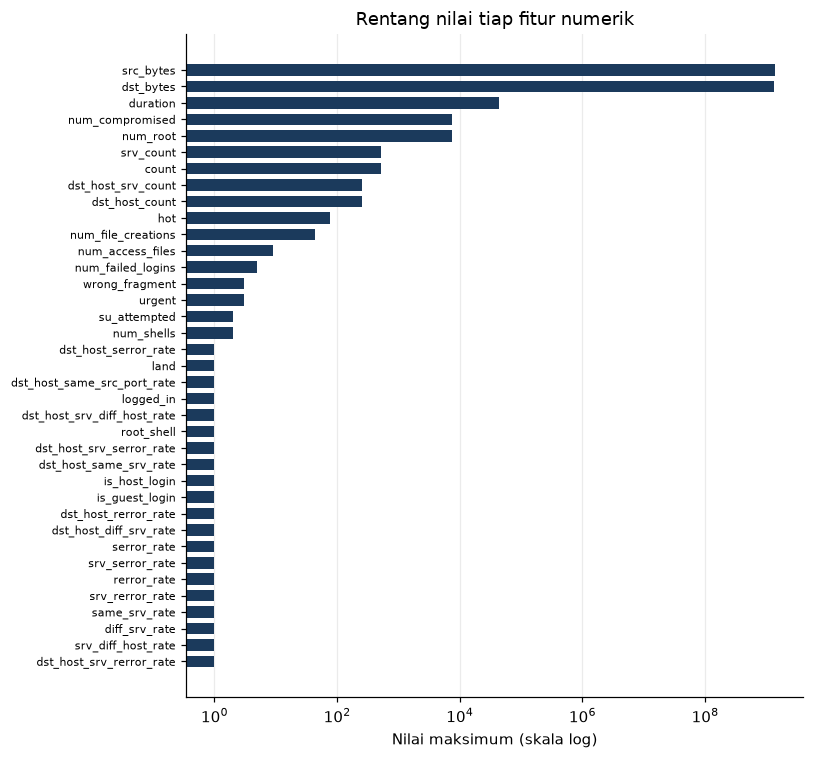

In [21]:
max_values = train_df[numeric].max().drop(constant).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(max_values.index, max_values.values, color=NAVY2, height=0.7)
ax.set_xscale("log")
ax.set_xlabel("Nilai maksimum (skala log)")
ax.set_title("Rentang nilai tiap fitur numerik")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

`src_bytes` bisa mencapai **1,3 miliar**, sementara fitur `*_rate` hanya 0–1. Jika dimasukkan apa adanya, fitur berskala besar akan mendominasi penjumlahan berbobot $z = \sum w_i x_i + b$ dan membuat *gradient descent* tidak stabil. Solusinya: ***standardization*** (`StandardScaler`) sehingga setiap fitur memiliki rata-rata 0 dan standar deviasi 1.

### 6.2 Sebaran sangat miring (*skewed*) dan banyak nol

In [22]:
zero_share = 100 * (train_df[numeric] == 0).mean().sort_values(ascending=False)
print(f"{(zero_share > 90).sum()} dari {len(numeric)} fitur numerik bernilai 0 pada >90% baris:")
print(zero_share[zero_share > 90].round(1).to_string())

16 dari 38 fitur numerik bernilai 0 pada >90% baris:
num_outbound_cmds     100.0
is_host_login         100.0
urgent                100.0
land                  100.0
num_shells            100.0
su_attempted           99.9
num_failed_logins      99.9
root_shell             99.9
num_file_creations     99.8
num_access_files       99.7
num_root               99.5
wrong_fragment         99.1
is_guest_login         99.1
num_compromised        99.0
hot                    97.9
duration               92.0


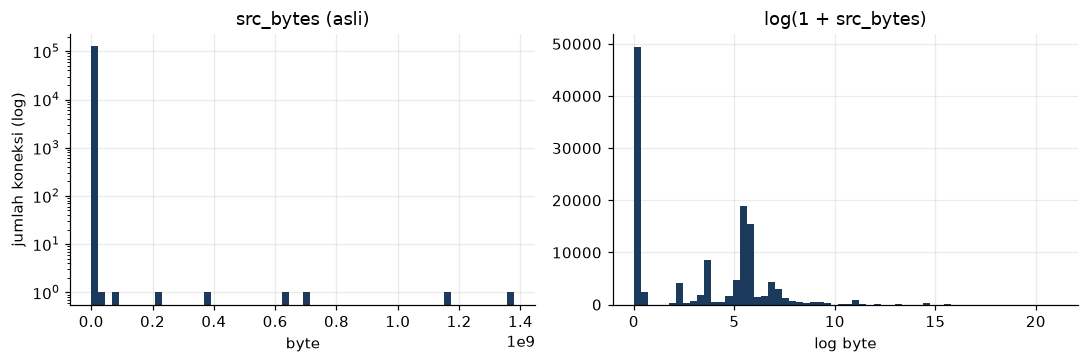

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(train_df["src_bytes"], bins=60, color=NAVY2)
axes[0].set_yscale("log")
axes[0].set_title("src_bytes (asli)")
axes[0].set_xlabel("byte")
axes[0].set_ylabel("jumlah koneksi (log)")

axes[1].hist(np.log1p(train_df["src_bytes"]), bins=60, color=NAVY2)
axes[1].set_title("log(1 + src_bytes)")
axes[1].set_xlabel("log byte")
plt.tight_layout()
plt.show()

Pada skala asli hampir semua data menumpuk di dekat 0 karena ada sedikit koneksi raksasa (*outlier*). Transformasi **logaritma** membuat polanya terlihat: ada kelompok koneksi 0 *byte* (banyak di antaranya serangan SYN *flood* yang tidak pernah mengirim data) dan kelompok koneksi normal ratusan–ribuan *byte*.

> *Pipeline* kita cukup memakai `StandardScaler`. Transformasi log adalah ide perbaikan yang bisa kamu coba sendiri.

### 6.3 Fitur apa yang membedakan normal dan serangan?

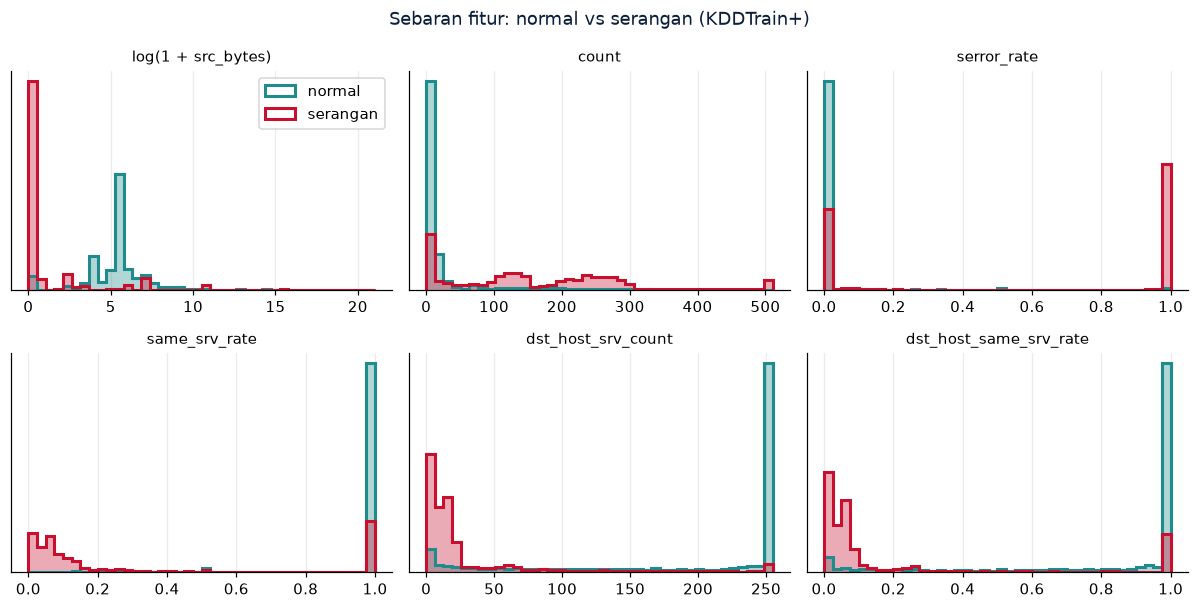

In [24]:
def plot_normal_vs_attack(ax, feature, log=False):
    # Histogram ternormalisasi: bentuk sebaran normal vs serangan
    values = np.log1p(train_df[feature]) if log else train_df[feature]
    bins = np.histogram_bin_edges(values, bins=40)
    for flag, color, name in [(0, TEAL, "normal"), (1, RED, "serangan")]:
        v = values[train_df["is_attack"] == flag]
        ax.hist(v, bins=bins, color=color, alpha=0.35, density=True)
        ax.hist(v, bins=bins, color=color, histtype="step", linewidth=2, density=True, label=name)
    ax.set_title(f"log(1 + {feature})" if log else feature, fontsize=10)
    ax.set_yticks([])


fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, (feature, log) in zip(axes.ravel(), [
    ("src_bytes", True), ("count", False), ("serror_rate", False),
    ("same_srv_rate", False), ("dst_host_srv_count", False), ("dst_host_same_srv_rate", False),
]):
    plot_normal_vs_attack(ax, feature, log)
axes[0, 0].legend()
fig.suptitle("Sebaran fitur: normal vs serangan (KDDTrain+)", color=NAVY)
plt.tight_layout()
plt.show()

Cara membaca: semakin **sedikit tumpang tindih** kurva hijau-toska dan merah, semakin berguna fitur tersebut.

- `count` — serangan DoS membuka **ratusan koneksi** ke host yang sama dalam 2 detik, sedangkan koneksi normal hanya sedikit.
- `serror_rate` — proporsi koneksi dengan *error* SYN. Hampir 0 untuk normal, hampir 1 untuk SYN *flood*.
- `same_srv_rate` dan `dst_host_same_srv_rate` — koneksi normal cenderung ke **layanan yang sama**, sedangkan *scanning* berpindah-pindah layanan.

Tidak ada satu fitur yang memisahkan kedua kelas secara sempurna. ANN bertugas **menggabungkan banyak fitur** untuk membentuk batas keputusan yang lebih baik.

### 6.4 Profil tiap kategori serangan

In [25]:
profile_cols = ["count", "serror_rate", "rerror_rate", "same_srv_rate",
                "logged_in", "num_failed_logins", "hot", "root_shell", "num_file_creations"]
train_df.groupby("category")[profile_cols].mean().reindex(CATEGORIES).style.format("{:,.2f}").background_gradient(axis=0, cmap="Blues")

,count,serror_rate,rerror_rate,same_srv_rate,logged_in,num_failed_logins,hot,root_shell,num_file_creations
category,,,,,,,,,
Normal,22.52,0.01,0.04,0.97,0.71,0.00,0.23,0.00,0.02
DoS,178.09,0.75,0.15,0.19,0.02,0.00,0.04,0.00,0.00
Probe,77.05,0.05,0.44,0.70,0.01,0.00,0.00,0.00,0.00
R2L,1.30,0.01,0.05,1.00,0.91,0.06,8.33,0.01,0.04
U2R,5.81,0.04,0.01,0.93,0.88,0.02,1.40,0.50,0.79


Tabel rata-rata di atas menunjukkan bahwa setiap kategori punya "sidik jari" sendiri:

- **DoS** — `count` dan `serror_rate` tinggi, `same_srv_rate` rendah: banjir koneksi yang gagal ke banyak *port*.
- **Probe** — `rerror_rate` paling tinggi (koneksi ditolak saat memindai *port*) dan `logged_in` hampir 0: hanya "mengetuk pintu", tidak masuk.
- **R2L** — `logged_in`, `num_failed_logins`, dan `hot` paling tinggi: mencoba masuk lewat *login* dan mengakses file sistem.
- **U2R** — `root_shell` (0,5) dan `num_file_creations` paling tinggi: sudah masuk, lalu berusaha menjadi *root*.

R2L dan U2R terlihat dari **fitur konten**, bukan dari volume trafik. Jumlah datanya pun sangat sedikit, sehingga keduanya paling sulit dideteksi.

---
## 7. Korelasi

### 7.1 Korelasi setiap fitur dengan label serangan

Korelasi Pearson antara fitur dan label biner (`is_attack`): mendekati **+1** berarti nilai fitur tinggi → cenderung serangan, mendekati **−1** berarti nilai tinggi → cenderung normal.

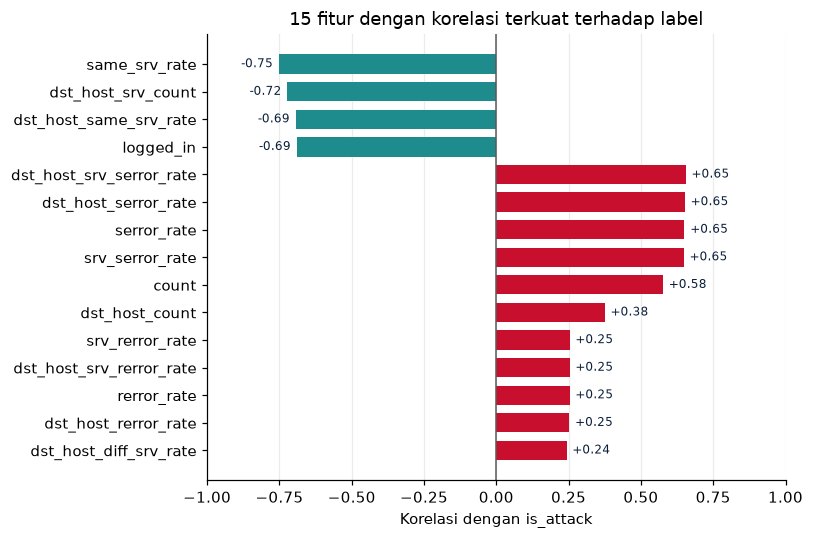

In [26]:
usable = [c for c in numeric if c not in constant]
corr_label = train_df[usable].corrwith(train_df["is_attack"])
top = corr_label.reindex(corr_label.abs().sort_values(ascending=False).index).head(15)[::-1]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(top.index, top.values, color=[RED if v > 0 else TEAL for v in top.values], height=0.7)
for y, v in enumerate(top.values):
    ax.text(v + (0.02 if v > 0 else -0.02), y, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=8, color=NAVY)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Korelasi dengan is_attack")
ax.set_title("15 fitur dengan korelasi terkuat terhadap label")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- **Positif** (merah): fitur-fitur `*serror_rate` dan `count` — ciri serangan DoS.
- **Negatif** (toska): `same_srv_rate`, `dst_host_srv_count`, `logged_in` — ciri koneksi normal yang "rapi".

> Korelasi hanya menangkap hubungan **linear**. Fitur dengan korelasi rendah belum tentu tidak berguna: ANN dengan aktivasi non-linear bisa memanfaatkan hubungan yang lebih rumit.

### 7.2 Korelasi antar fitur

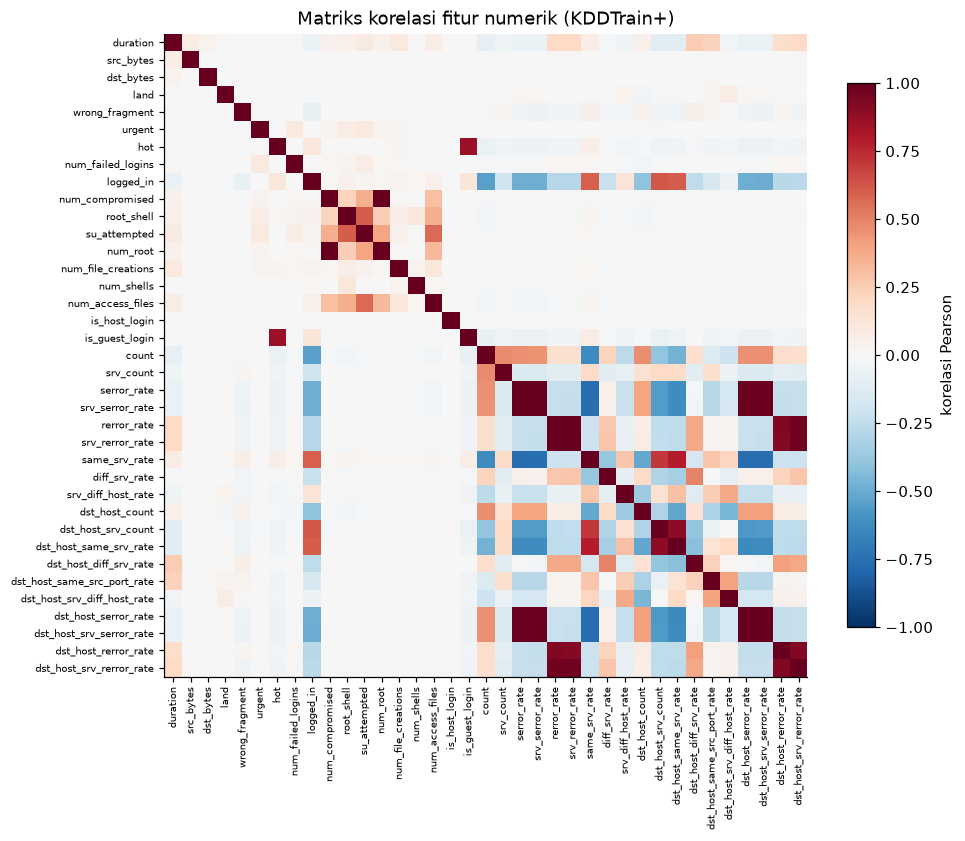

In [27]:
corr = train_df[usable].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(usable)), usable, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(usable)), usable, fontsize=6.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="korelasi Pearson")
ax.set_title("Matriks korelasi fitur numerik (KDDTrain+)")
plt.tight_layout()
plt.show()

In [28]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # ambil segitiga atas saja
redundant = upper.stack().loc[lambda s: s.abs() > 0.95].sort_values(ascending=False)
print(f"{len(redundant)} pasangan fitur dengan |korelasi| > 0,95:")
print(redundant.round(3).to_string())

10 pasangan fitur dengan |korelasi| > 0,95:
num_compromised       num_root                    0.999
serror_rate           srv_serror_rate             0.993
rerror_rate           srv_rerror_rate             0.989
srv_serror_rate       dst_host_srv_serror_rate    0.986
dst_host_serror_rate  dst_host_srv_serror_rate    0.985
serror_rate           dst_host_srv_serror_rate    0.981
                      dst_host_serror_rate        0.979
srv_serror_rate       dst_host_serror_rate        0.978
srv_rerror_rate       dst_host_srv_rerror_rate    0.970
rerror_rate           dst_host_srv_rerror_rate    0.964


Ada kelompok fitur yang **hampir identik** (mis. `serror_rate`, `srv_serror_rate`, `dst_host_serror_rate`). Fitur yang redundan tidak merusak ANN, tetapi menambah parameter tanpa menambah informasi. Di tahap lanjut, fitur seperti ini bisa dikurangi (*feature selection*).

---
## 8. Data Latih vs Data Uji

Kolom `difficulty` menyatakan berapa dari 21 model *machine learning* (dalam penelitian pembuat dataset) yang berhasil menebak record tersebut dengan benar. Nilai **21 = mudah**, nilai kecil = **sulit**.

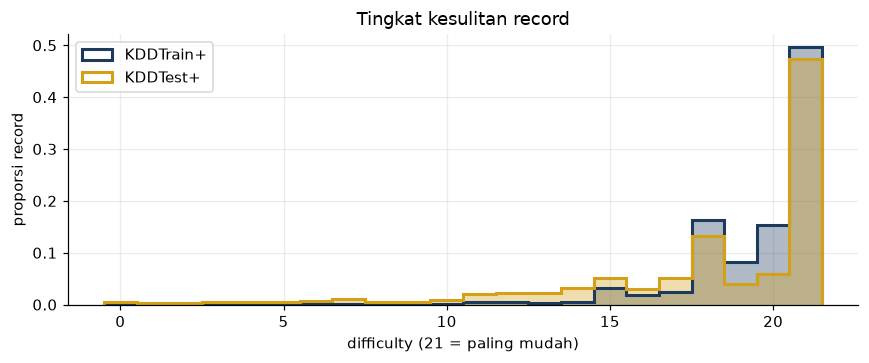

KDDTrain+  record sulit (difficulty < 18):  10.4%
KDDTest+   record sulit (difficulty < 18):  29.5%


In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(-0.5, 22.5, 1)
ax.hist(train_df["difficulty"], bins=bins, density=True, color=NAVY2, alpha=0.35)
ax.hist(train_df["difficulty"], bins=bins, density=True, histtype="step", linewidth=2, color=NAVY2, label="KDDTrain+")
ax.hist(test_df["difficulty"], bins=bins, density=True, color=GOLD, alpha=0.35)
ax.hist(test_df["difficulty"], bins=bins, density=True, histtype="step", linewidth=2, color=GOLD, label="KDDTest+")
ax.set_xlabel("difficulty (21 = paling mudah)")
ax.set_ylabel("proporsi record")
ax.set_title("Tingkat kesulitan record")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

for name, df in [("KDDTrain+", train_df), ("KDDTest+", test_df)]:
    print(f"{name:10s} record sulit (difficulty < 18): {100 * (df['difficulty'] < 18).mean():5.1f}%")

Data uji jauh lebih banyak berisi record sulit, ditambah 17 jenis serangan baru (Bagian 4.3). Jadi **wajar jika akurasi di KDDTest+ lebih rendah daripada akurasi validasi** yang diambil dari KDDTrain+. Ini bukan *bug*, melainkan gambaran jujur kemampuan generalisasi model.

---
## 9. Ringkasan Temuan → Keputusan *Preprocessing*

| Temuan EDA | Keputusan di *pipeline* (`preprocessing.py`) |
|---|---|
| Tidak ada *missing value* & duplikat | Tidak perlu pembersihan data |
| `difficulty` adalah metadata | Dibuang sebelum training |
| 23 jenis label, 4 kategori serangan | Digabung menjadi **label biner** (`make_labels`) |
| 3 fitur teks (3 + 70 + 11 nilai) | ***One-hot encoding*** → **122 fitur** (`encode_features`) |
| Skala fitur berbeda hingga 10⁹ kali | ***Standardization***, *scaler* hanya di-*fit* pada data latih (`scale_features`) |
| Kelas tidak seimbang | `stratify` saat split + metrik *precision*, *recall*, F1 |
| Serangan baru & record sulit di data uji | Akurasi uji < akurasi validasi adalah hal yang wajar |
| `num_outbound_cmds` konstan, beberapa fitur redundan | Dibiarkan (ANN tetap bisa belajar); kandidat *feature selection* |

**Berikutnya:** jalankan `uv run python sesi-1-ann/train.py` dan lihat bagaimana keputusan-keputusan di atas diterapkan.

---
## Latihan

**Latihan 1.** Ubah `feature` di sel berikut ke fitur lain (mis. `"dst_host_serror_rate"`, `"logged_in"`, `"dst_bytes"`). Fitur mana yang paling jelas memisahkan normal dan serangan? Apakah hasilnya cocok dengan grafik korelasi di Bagian 7.1?

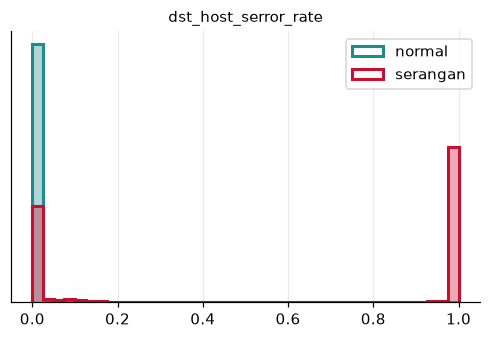

Korelasi dst_host_serror_rate dengan is_attack: +0.652


In [30]:
feature = "dst_host_serror_rate"   # <- ganti di sini
use_log = False                    # True untuk fitur berskala besar seperti src_bytes / dst_bytes

fig, ax = plt.subplots(figsize=(5.5, 3.2))
plot_normal_vs_attack(ax, feature, log=use_log)
ax.legend()
plt.show()
print(f"Korelasi {feature} dengan is_attack: {train_df[feature].corr(train_df['is_attack']):+.3f}")

**Latihan 2.** Proporsi serangan per `protocol_type` di data **latih** sudah kita lihat di Bagian 5. Bagaimana di data **uji**? Jalankan sel berikut dan bandingkan. Protokol mana yang proporsi serangannya berubah paling besar?

In [31]:
compare = pd.DataFrame({
    "serangan latih (%)": 100 * train_df.groupby("protocol_type")["is_attack"].mean(),
    "serangan uji (%)": 100 * test_df.groupby("protocol_type")["is_attack"].mean(),
})
compare.round(1)

,serangan latih (%),serangan uji (%)
protocol_type,,
icmp,84.2,91.1
tcp,47.8,58.5
udp,17.1,32.2


**Latihan 3.** Jika fitur `service` **dibuang**, berapa jumlah input MLP setelah *one-hot encoding*? Hitung di kertas dulu (lihat Bagian 5.3), lalu cek:

In [32]:
reduced = pd.get_dummies(train_df[FEATURES].drop(columns=["service"]), columns=["protocol_type", "flag"])
print("Jumlah fitur tanpa service:", reduced.shape[1])

Jumlah fitur tanpa service: 52
